# **Inference-Time Scaling Via Self-Refinement**

## **Loading the Pretrained Model**

In [1]:
from pathlib import Path
import torch
from reasoning_from_scratch.qwen3 import (
    download_qwen3_small,
    Qwen3Tokenizer,
    Qwen3Model,
    QWEN_CONFIG_06_B
)
from ipynb.fs.full.generating_text_qwen_3 import get_device


def load_model_and_tokenizer(
    which_model, device, use_compile, local_dir="qwen3"
):
    if which_model == "base":

        download_qwen3_small(
            kind="base", tokenizer_only=False, out_dir=local_dir
        )

        tokenizer_path = Path(local_dir) / "tokenizer-base.json"
        model_path = Path(local_dir) / "qwen3-0.6B-base.pth"
        tokenizer = Qwen3Tokenizer(tokenizer_file_path=tokenizer_path)

    elif which_model == "reasoning":

        download_qwen3_small(
            kind="reasoning", tokenizer_only=False, out_dir=local_dir
        )

        tokenizer_path = Path(local_dir) / "tokenizer-reasoning.json"
        model_path = Path(local_dir) / "qwen3-0.6B-reasoning.pth"
        tokenizer = Qwen3Tokenizer(
            tokenizer_file_path=tokenizer_path,
            apply_chat_template=True,
            add_generation_prompt=True,
            add_thinking=True,
        )

    else:
        raise ValueError(f"Invalid choice: which_model={which_model}")

    model = Qwen3Model(QWEN_CONFIG_06_B)
    model.load_state_dict(torch.load(model_path))

    model.to(device)

    if use_compile:
        torch._dynamo.config.allow_unspec_int_on_nn_module = True
        model = torch.compile(model)

    return model, tokenizer

Tokenizer is Already downloaded at path:  qwen3\tokenizer-base.json
Model is Already downloaded at path: qwen3\qwen3-0.6B-base.pth
Total time taken to download QWEN-3(small 0.6B): 0.0009670257568359375
 in the middle of the in the middle of the

Time: 10.51 sec
0 tokens/sec
 in the middle of the

Time: 2.61 sec
1 tokens/sec


In [2]:
import torch
from ipynb.fs.full.generating_text_qwen_3 import get_device

device = get_device()

model, tokenizer = load_model_and_tokenizer(
    which_model="base",
    device=device,
    use_compile=False
)

✓ qwen3\qwen3-0.6B-base.pth already up-to-date


Try the model on a prompt from the MATH-500 dataset,

In [3]:
from ipynb.fs.defs.inference_time_scaling import  (
    generate_text_stream_concat_flex,
    generate_text_top_p_stream_cache
)

from ipynb.fs.defs.evaluating_model_math import render_prompt

raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)
prompt_cot = prompt + "\n\nExplain step by step."

torch.manual_seed(0)
response_1 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.9,
    top_p=0.9
)



 ### Step 1: Understand the problem

The problem states that half the value of \(3x - 9\) is equal to \(x + 37\). We need to find the value of \(x\).

### Step 2: Translate the problem into an equation

Let's translate the given statement into an equation. Half of \(3x - 9\) is equal to \(x + 37\).

\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 3: Solve the equation

To solve for \(x\), we'll first eliminate the fraction by multiplying both sides of the equation by 2:

\[
2 \times \frac{1}{2}(3x - 9) = 2 \times (x + 37)
\]

This simplifies to:

\[
3x - 9 = 2x + 74
\]

### Step 4: Isolate the variable \(x\)

Now, we'll isolate \(x\) by subtracting \(2x\) from both sides of the equation:

\[
3x - 2x - 9 = 74
\]

Simplifying this, we get:

\[
x - 9 = 74
\]

### Step 5: Solve for \(x\)

Next, we'll add 9 to both sides to solve for \(x\):

\[
x - 9 + 9 = 74 + 9
\]

This simplifies to:

\[
x = 83
\]

### Step 6: Verify the solution

To ensure our solution is correct, we'll substitute \(x = 83

In [4]:
torch.manual_seed(3)
response_2 = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.9,
    top_p=0.9, 
)

 We start with the equation:

\[
\frac{1}{2} \times (3x - 9) = x + 37
\]

Step 1: Multiply both sides of the equation by 2 to eliminate the fraction:

\[
2 \times \frac{1}{2} \times (3x - 9) = 2 \times (x + 37)
\]

Simplifying both sides:

\[
3x - 9 = 2x + 74
\]

Step 2: Subtract \(2x\) from both sides to get all the \(x\) terms on one side:

\[
3x - 2x - 9 = 74
\]

Simplifying:

\[
x - 9 = 74
\]

Step 3: Add 9 to both sides to isolate \(x\):

\[
x - 9 + 9 = 74 + 9
\]

Simplifying:

\[
x = 83
\]

Final Answer:

\[
\boxed{83}
\]

In [5]:
print("Response 1 characters:", len(response_1))
print("Response 1 tokens:", len(tokenizer.encode(response_1)))
print("\nResponse 2 characters:", len(response_2))
print("Response 2 tokens:", len(tokenizer.encode(response_2)))

Response 1 characters: 1419
Response 1 tokens: 534

Response 2 characters: 533
Response 2 tokens: 231


## **Scoring LLM responses with a rule-based score**

In [6]:
from ipynb.fs.defs.evaluating_model_math import extract_final_candidate
import math

def heuristic_score(
    answer,
    prompt=None,  # Placeholder that is ignored
    brevity_bonus=500.0,
    boxed_bonus=2.0,
    extract_bonus=1.0,
    fulltext_bonus=0.0,
):
    score = 0.0

    # Reward answers that have a final boxed value
    cand = extract_final_candidate(answer, fallback=None)
    if cand:
        score += boxed_bonus

    # Give weaker rewards if answer doesn't have a boxed value
    else:
        cand = extract_final_candidate(answer, fallback="number_only")
        if cand:
            score += extract_bonus
        else:
            cand = extract_final_candidate(
                answer, fallback="number_then_full"
            )
            if cand:
                score += fulltext_bonus

    # Add a brevity reward that decays with text length
    score += 1.5 * math.exp(-len(answer) / brevity_bonus)
    return score

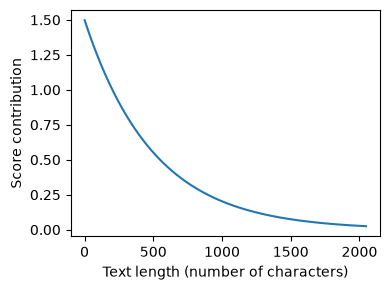

In [7]:
import matplotlib.pyplot as plt

def plot_brevity_curve(brevity_bonus, max_len=2048):
    lengths = torch.arange(1, max_len)
    scores = 1.5 * torch.exp(-lengths / brevity_bonus)

    plt.figure(figsize=(4, 3))
    plt.plot(lengths, scores)
    plt.xlabel("Text length (number of characters)")
    plt.ylabel("Score contribution")
    plt.tight_layout()
    #plt.savefig("brevity_curve.pdf")
    plt.show()

plot_brevity_curve(500)

Graph is showing that as the size of answer increases, score becomes smaller and smaller

In [8]:
print(round(heuristic_score(response_1), 3))

print(round(heuristic_score(response_2), 3))

2.088
2.517


## **Understanding token probability scores**

In [9]:
@torch.inference_mode()
def calc_next_token_probas(model, tokenizer, prompt, device, show=True):

    token_ids = torch.tensor(tokenizer.encode(prompt), device=device)

    # Get logits and probabilities similar to text generation functions
    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    all_probas = torch.softmax(logits, dim=-1)

    # Positions we score (here: all)
    t_idx = torch.arange(0, token_ids.shape[0] - 1, device=device)

    # Since we have the text, we know the true next tokens
    next_ids = token_ids[1:]

    # Get probabilities for each next token
    next_token_probas = all_probas[t_idx, next_ids]

    # Likelihood of the sequence is the product of the probability scores
    prod_next_token_probas = torch.prod(next_token_probas)

    if show:
        print("Next-token probabilities:", next_token_probas)
        print("Joint probability:", prod_next_token_probas)

    else:
        return next_token_probas, prod_next_token_probas

In [10]:
torch.set_printoptions(precision=4, sci_mode=True)

In [11]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Berlin"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 1.5625e-01],
       dtype=torch.bfloat16)
Joint probability: tensor(4.7730e-08, dtype=torch.bfloat16)


In [12]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Bridge"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 3.0175e-07],
       dtype=torch.bfloat16)
Joint probability: tensor(9.2371e-14, dtype=torch.bfloat16)


In [14]:
calc_next_token_probas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Hamburg"
    )

Next-token probabilities: tensor([5.7936e-05, 4.4141e-01, 1.6113e-02, 7.3828e-01, 3.0762e-02],
       dtype=torch.bfloat16)
Joint probability: tensor(9.3714e-09, dtype=torch.bfloat16)


In [15]:
torch.set_printoptions(precision=4, sci_mode=False)

logits = torch.linspace(-2, 2, steps=7)
probas = torch.softmax(logits, dim=-1)
print(probas)

print(torch.log(probas))

log_probas = torch.log_softmax(logits, dim=-1)
print(log_probas)



tensor([0.0090, 0.0175, 0.0341, 0.0665, 0.1295, 0.2522, 0.4912])
tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])
tensor([-4.7109, -4.0442, -3.3776, -2.7109, -2.0442, -1.3776, -0.7109])


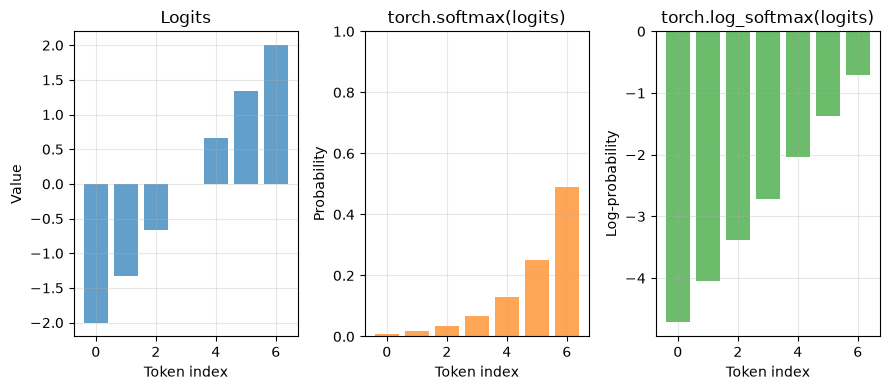

In [16]:
plt.figure(figsize=(9, 4))

# Logits
plt.subplot(1, 3, 1)
plt.bar(range(len(logits)), logits, color="C0", alpha=0.7)
plt.title("Logits")
plt.xlabel("Token index")
plt.ylabel("Value")
plt.grid(alpha=0.3)

# Softmax
plt.subplot(1, 3, 2)
plt.bar(range(len(probas)), probas, color="C1", alpha=0.7)
plt.title("torch.softmax(logits)")
plt.xlabel("Token index")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.grid(alpha=0.3)

# Log-softmax
plt.subplot(1, 3, 3)
plt.bar(range(len(log_probas)), log_probas, color="C2", alpha=0.7)
plt.title("torch.log_softmax(logits)")
plt.xlabel("Token index")
plt.ylabel("Log-probability")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("logits_softmax_log_softmax.pdf")
plt.show()


## **From token probability scores to log-probabilities**

In [17]:
@torch.inference_mode()
def calc_next_token_logprobas(model, tokenizer, prompt, device, show=True):

    token_ids = torch.tensor(tokenizer.encode(prompt), device=device)

    logits = model(token_ids.unsqueeze(0)).squeeze(0)
    # We now use log_softmax
    all_logprobas = torch.log_softmax(logits, dim=-1)

    t_idx = torch.arange(0, token_ids.shape[0] - 1, device=device)
    next_ids = token_ids[1:]
    next_token_logprobas = all_logprobas[t_idx, next_ids]

    # We replace the product with a sum
    sum_next_token_logprobas = torch.sum(next_token_logprobas)

    if show:
        print("Next-token log-probabilities:", next_token_logprobas)
        print("Joint log-probability:", sum_next_token_logprobas)
    else:
        return next_token_logprobas, sum_next_token_logprobas

In [18]:
calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Berlin"
    )

Next-token log-probabilities: tensor([-9.7500, -0.8164, -4.1250, -0.3008, -1.8594], dtype=torch.bfloat16)
Joint log-probability: tensor(-16.8750, dtype=torch.bfloat16)


In [19]:
calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Bridge"
    )

Next-token log-probabilities: tensor([ -9.7500,  -0.8164,  -4.1250,  -0.3008, -15.0000],
       dtype=torch.bfloat16)
Joint log-probability: tensor(-30., dtype=torch.bfloat16)


In [20]:
calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt="The capital of Germany is Hamburg"
    )

Next-token log-probabilities: tensor([-9.7500, -0.8164, -4.1250, -0.3008, -3.4844], dtype=torch.bfloat16)
Joint log-probability: tensor(-18.5000, dtype=torch.bfloat16)


## **Scoring model confidence with log-probabilities**

In [21]:
example_prompt = "What is the capital of Germany?"
example_answer = " The capital of Germany is Berlin."

next_token_logprobas, sum_next_token_logprobas = calc_next_token_logprobas(
        model, tokenizer, device=device,
        prompt=example_prompt+example_answer,
        show=False
    )

print("Next-token logprobas:", next_token_logprobas)
print("Joint log-probability:", sum_next_token_logprobas)

Next-token logprobas: tensor([-0.4512, -0.3574, -8.3125, -0.4062, -3.8438, -2.9688, -1.1328,  0.0000,
        -0.0232,  0.0000, -0.0078, -0.0679, -0.1523], dtype=torch.bfloat16)
Joint log-probability: tensor(-17.7500, dtype=torch.bfloat16)


In [22]:
print(len(tokenizer.encode(example_answer)))

7


In [23]:
@torch.inference_mode()
def avg_logprob_answer(model, tokenizer, prompt, answer, device="cpu"):

    # Encode prompt and answer tokens separately to get the prompt length later
    prompt_ids = tokenizer.encode(prompt)
    answer_ids = tokenizer.encode(answer)
    full_ids = torch.tensor(prompt_ids + answer_ids, device=device)

    # Same as in calc_next_token_logprobas before
    logits = model(full_ids.unsqueeze(0)).squeeze(0)
    logprobs = torch.log_softmax(logits, dim=-1)

    # Index range for positions corresponding to answer tokens
    start = len(prompt_ids) - 1
    end = full_ids.shape[0] - 1

    # Same as before, except for using start and end
    t_idx = torch.arange(start, end, device=device)
    next_tokens = full_ids[start + 1 : end + 1]
    next_token_logps = logprobs[t_idx, next_tokens]

    # Average over the answer token scores
    return torch.mean(next_token_logps)

In [24]:
score_1 = avg_logprob_answer(
    model, tokenizer,
    prompt="What is the capital of Germany?",
    answer=" The capital of Germany is Berlin.",
    device=device
)
print(score_1)

tensor(-0.1973, dtype=torch.bfloat16)


In [25]:
score_2 = avg_logprob_answer(
    model, tokenizer,
    prompt="What is the capital of Germany?",
    answer=" The capital of Germany is Bridge.",
    device=device
)
print(score_2)

tensor(-3.8750, dtype=torch.bfloat16)


In [26]:
avg_logprob_answer(
    model, tokenizer,
    prompt=prompt_cot,
    answer=response_1,
    device=device
)


avg_logprob_answer(
    model, tokenizer,
    prompt=prompt_cot,
    answer=response_2,
    device=device
)

tensor(-0.1104, dtype=torch.bfloat16)

## **Self-refinement through iterative feedback**

In [27]:
raw_prompt = (
    "Half the value of $3x-9$ is $x+37$. "
    "What is the value of $x$?"
)
prompt = render_prompt(raw_prompt)

torch.manual_seed(123)
initial_response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7,
    top_p=0.9, 
)

 \boxed{18}

In [28]:
def make_critique_prompt(raw_prompt, draft):
    return (
        "You are a meticulous reviewer. Identify logical errors, missing "
        "steps, or arithmetic mistakes. If the answer seems correct, "
        "say so briefly. Then propose a concise plan to fix issues.\n\n"
        f"Question:\n{raw_prompt}\n\n"
        f"Draft answer:\n{draft}\n\n"
        "Write a short critique and bullet-point fix plan "
        "(under ~120 words).\n"
        "Critique:"
    )


critique_prompt = make_critique_prompt(raw_prompt, initial_response)
torch.manual_seed(123)
critique = generate_text_stream_concat_flex(
    model, tokenizer, critique_prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7,
    top_p=0.9, 
)

 The problem seems to have a typo. The equation is supposed to be half the value of $3x - 9$ is $x + 37$, not $3x - 9$ is $x + 37$.

Fix Plan: The equation should be written as "half the value of $3x - 9$ is $x + 37$". To solve for $x$, follow these steps:

1. Start with the equation: $\frac{1}{2}(3x - 9) = x + 37$
2. Multiply both sides by 2 to eliminate the fraction: $3x - 9 = 2(x + 37)$
3. Distribute the 2 on the right side: $3x - 9 = 2x + 74$
4. Subtract $2x$ from both sides to get $x - 9 = 74$
5. Add 9 to both sides to get $x = 83$

In [32]:
def make_refine_prompt(raw_prompt, draft, critique):
    return (
        "Revise the answer using the critique. Keep it concise and "
        "end with a final boxed result: \\boxed{ANSWER}\n\n"
        f"Question:\n{raw_prompt}\n\n"
        f"Previous answer:\n{draft}\n\n"
        f"Critique:\n{critique}\n\n"
        "Revised answer:"
    )

refine_prompt = make_refine_prompt(raw_prompt, initial_response, critique)
torch.manual_seed(123)
revised_answer = generate_text_stream_concat_flex(
    model, tokenizer, refine_prompt, device,
    max_new_tokens=2048, verbose=True,
    generate_func=generate_text_top_p_stream_cache,
    temperature=0.7,
    top_p=0.9, 
)

 \boxed{83}

Final boxed result: \boxed{83}

## **Coding Self-refinement Loop**

In [29]:
def self_refinement_loop(
    model,
    tokenizer,
    raw_prompt,
    device,
    iterations=2,
    max_response_tokens=2048,
    max_critique_tokens=256,
    score_fn=None,
    prompt_renderer=render_prompt,
    prompt_suffix="",
    verbose=False,
    temperature=0.7,
    top_p=0.9,
):
    steps = []

    # Initial response (draft)
    prompt = prompt_renderer(raw_prompt) + prompt_suffix
    current_full = generate_text_stream_concat_flex(
        model=model,
        tokenizer=tokenizer,
        prompt=prompt,
        device=device,
        max_new_tokens=max_response_tokens,
        verbose=False,
        generate_func=generate_text_top_p_stream_cache,
        temperature=temperature,
        top_p=top_p,
    )

    current_extracted = extract_final_candidate(
        current_full, fallback="number_then_full"
    )
    if score_fn:
        current_score = score_fn(answer=current_full, prompt=prompt)
    else:
        current_score = 0.0

    # Run for one or more iterations
    for it in range(iterations):
        draft_before_full = current_full
        draft_before_extracted = current_extracted
        score_before = current_score

        # Critique the response
        critique_prompt = make_critique_prompt(
            raw_prompt, draft_before_full
        )
        critique_full = generate_text_stream_concat_flex(
            model=model,
            tokenizer=tokenizer,
            prompt=critique_prompt,
            device=device,
            max_new_tokens=max_critique_tokens,
            verbose=False,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature,
            top_p=top_p,
        )

        # Refine the response
        refine_prompt = make_refine_prompt(
            raw_prompt, draft_before_full, critique_full
        )
        revised_full = generate_text_stream_concat_flex(
            model=model,
            tokenizer=tokenizer,
            prompt=refine_prompt,
            device=device,
            max_new_tokens=max_response_tokens,
            verbose=False,
            generate_func=generate_text_top_p_stream_cache,
            temperature=temperature,
            top_p=top_p,
        )

        revised_extracted = extract_final_candidate(
            revised_full, fallback="number_then_full"
        )
        if score_fn:
            revised_score = score_fn(
                answer=revised_full, prompt=prompt  # Still use original prompt here
            )
        else:
            revised_score = 0.0
        
        # Log the results
        step = {
            "iteration": it + 1,
            "draft_full": draft_before_full,
            "draft_extracted": draft_before_extracted,
            "critique": critique_full,
            "revised_full": revised_full,
            "revised_extracted": revised_extracted,
            "score_before": score_before,
            "score_after": revised_score,
        }
        steps.append(step)

        if verbose:
            print(
                f"[Refinement {it+1}/{iterations}]"
                f"\nCurrent: {draft_before_extracted}"
                f"\nRevised: {revised_extracted}"
                f"\nScore before: {score_before:.3f}"
                f"\nScore after: {revised_score:.3f}"
                f"\n{'=' * 25}"
            )

        # Accept revised response if it's not worse
        if revised_score >= current_score:
            current_full = revised_full
            current_extracted = revised_extracted
            current_score = revised_score

    return {
        "final_full": current_full,
        "final_extracted": current_extracted,
        "steps": steps,
    }

In [30]:
from functools import partial

avg_logprob_score = partial(
    avg_logprob_answer,
    model=model,
    tokenizer=tokenizer,
    device=device
)

In [31]:
torch.manual_seed(1)

results_logprob = self_refinement_loop(
    model=model,
    tokenizer=tokenizer,
    raw_prompt=raw_prompt,
    device=device,
    iterations=2,
    max_response_tokens=2048,
    max_critique_tokens=256,
    score_fn=avg_logprob_score,
    verbose=True,
    temperature=0.7,
    top_p=0.9,
)

NameError: name 'make_refine_prompt' is not defined